Nama: Johansen Tan
NIM: 2702241710

In [ ]:
import pandas as pd
from matplotlib import pyplot as plt

In [ ]:
df = pd.read_csv('balanced_data.csv')
df.head()

,Unnamed: 0,content,score
0,0,always gets disconnected,1
1,1,"can't find anything, old app is better",1
2,2,Totally rubbish now.,1
3,3,puzzles broken. cant see solution. literally o...,1
4,4,it shows me there are currently ~30.000 games....,1


# Remove Broken Data

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  3000 non-null   int64 
 1   content     2999 non-null   object
 2   score       3000 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 70.4+ KB
None


In [ ]:
df.drop('Unnamed: 0', axis=1, inplace=True)

In [ ]:
print(df.isnull().sum())
df.dropna(subset=['content'], inplace=True)

content    1
score      0
dtype: int64


In [ ]:
print(df.duplicated().sum())
df.drop_duplicates(inplace=True)

120


In [ ]:
# check non alphabetical words
from collections import Counter
def get_non_alpha_words(text):
  words = str(text).split()
  non_alpha = [word for word in words if not word.isalpha()]
  return non_alpha

all_non_alpha_words = []
for content in df['content']:
  all_non_alpha_words.extend(get_non_alpha_words(content))

non_alpha_counts = Counter(all_non_alpha_words)
print("Words with non-alphabetical characters:")
print(non_alpha_counts.most_common(50))

Words with non-alphabetical characters:
[("it's", 231), ("don't", 169), ("can't", 155), ('app.', 143), ("I'm", 131), ("It's", 109), ('game.', 86), ("doesn't", 85), ('app,', 75), ('1', 69), ('5', 68), ('2', 68), ('chess.', 61), ('it.', 60), (',', 59), ('game,', 57), ("I've", 55), ('3', 54), ('.', 52), ('time.', 48), ('games.', 38), ('10', 37), ('4', 36), ("didn't", 35), ('me.', 31), ("that's", 30), ('👍', 30), ('it,', 27), ('ads.', 27), ("isn't", 26), ('this.', 25), ('out.', 24), ("won't", 24), ('free.', 24), ('puzzles,', 23), ("there's", 23), ('now.', 22), ('&', 22), ("Can't", 21), ('good.', 20), ('-', 20), ('chess,', 20), ("you're", 20), ('experience.', 19), ('move.', 19), ('games,', 19), ("I'll", 17), ('work.', 17), ("aren't", 17), ('30', 17)]


In [ ]:
# check non ascii words
from collections import Counter
def get_non_ascii_words(text):
  words = str(text).split()
  non_ascii = [word for word in words if any(ord(char) > 127 for char in word)]
  return non_ascii

all_non_ascii_words = []
for content in df['content']:
  all_non_ascii_words.extend(get_non_ascii_words(content))

non_ascii_counts = Counter(all_non_ascii_words)
print("Words with non-ascii characters:")
print(non_ascii_counts.most_common(50))

Words with non-ascii characters:
[('👍', 30), ('👌', 8), ('♟️', 7), ('не', 6), ('و', 5), ('в', 5), ('😭', 4), ('😕', 4), ('😊', 4), ('😀', 4), ('😎', 4), ('и', 3), ('في', 3), ('😔', 3), ('مش', 3), ('👍🏻', 3), ('👍👍', 3), ('😭.', 3), ('💔', 3), ('🎮', 3), ('👎', 2), ('🌟', 2), ('—', 2), ('möglich.', 2), ('как', 2), ('с', 2), ('на', 2), ('🙂🙂🙂🙂🙂', 2), ('😜', 2), ('так', 2), ('😒', 2), ('👎👎👎', 2), ('часто', 2), ('👎🏻', 2), ('если', 2), ('то', 2), ('всё', 2), ('☹️', 2), ('⚠️', 2), ('😃', 2), ('👍🏼', 2), ('звуковата', 2), ('индикация', 2), ('шах,', 2), ('😐', 2), ('it’s', 2), ('I’ve', 2), ('🙏', 2), ('❤', 2), ('🤔', 2)]


In [ ]:
# check how mamy rows with non ascii characters (might delete them)
non_ascii_mask = df['content'].apply(lambda x: any(ord(char) > 127 for char in str(x)))

num_rows_with_non_ascii = non_ascii_mask.sum()

print(f"Number of rows with non ascii characters: {num_rows_with_non_ascii}")
print(f"Percentage of dataset: {(num_rows_with_non_ascii / len(df)) * 100:.2f}%")

print("\nSample rows containing non ascii characters:")
print(df[non_ascii_mask]['content'].head(10))

Number of rows with non ascii characters: 291
Percentage of dataset: 10.11%

Sample rows containing non ascii characters:
15     Here’s a more professional version: The server...
19     i lost so many games because of loading thing ...
24                                       get lost 👎👎👎0/5
47                    -III 🌟 Star Big fraud with player.
55     Worst experience Why lichess operators are giv...
60                    Nothing work normally in the app 😭
65     I can't make my account। it is saying that lic...
73     This app is just a waste of time. They make yo...
81     My first account got banned before I entered t...
114                                              有病平的算0分
Name: content, dtype: object


In [ ]:
df_ascii_only = df[~non_ascii_mask]
print(f"With non ascii: {len(df)}")
print(f"Without non ascii: {len(df_ascii_only)}")
# this is still appropriate

With non ascii: 2879
Without non ascii: 2588


In [ ]:
# check longest and shortest sentence
df_ascii_only['word_count'] = df_ascii_only['content'].apply(lambda x: len(str(x).split()))
df_ascii_only['char_count'] = df_ascii_only['content'].apply(lambda x: len(str(x)))

# 2. See the Statistics (Mean, Min, Max)
print(df_ascii_only[['word_count', 'char_count']].describe())

pd.set_option('display.max_colwidth', None)

print("Longest Sentences")
longest = df_ascii_only.nlargest(10, 'word_count')
print(longest[['word_count', 'content']])

print("Shortest Sentences")
shortest = df_ascii_only.nsmallest(10, 'word_count')
print(shortest[['word_count', 'content']])

pd.reset_option('display.max_colwidth')

        word_count   char_count
count  2588.000000  2588.000000
mean     22.042117   117.947063
std      22.441061   120.087122
min       1.000000     2.000000
25%       6.000000    31.000000
50%      14.000000    75.000000
75%      31.000000   165.000000
max     108.000000   500.000000
Longest Sentences
      word_count  \
2701         108   
616          103   
1928         103   
1580         102   
917          101   
68           100   
434          100   
2715         100   
171           99   
1740          99   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                         

/tmp/ipykernel_9058/4117614586.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ascii_only['word_count'] = df_ascii_only['content'].apply(lambda x: len(str(x).split()))
/tmp/ipykernel_9058/4117614586.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ascii_only['char_count'] = df_ascii_only['content'].apply(lambda x: len(str(x)))


In [ ]:
import numpy as np

# check 95th and 99th percentile
p95 = np.percentile(df_ascii_only['word_count'], 95)
p99 = np.percentile(df_ascii_only['word_count'], 99)

print(f"Average length: {df_ascii_only['word_count'].mean():.2f}")
print(f"95th percentile length: {p95}")
print(f"99th percentile length: {p99}")

Average length: 22.04
95th percentile length: 75.0
99th percentile length: 94.0


In [ ]:
# english words normally don't exceed 25 letter count
# those long comments look like spam or tags only, capping at 100 words
is_garbage_word = (df_ascii_only['word_count'] == 1) & (df_ascii_only['char_count'] > 25)
is_spam_length = (df_ascii_only['word_count'] > 100)
final_mask = is_garbage_word | is_spam_length
df_cleaned = df_ascii_only[~final_mask].copy()

In [ ]:
# Count the totals for each score
print(df_cleaned['score'].value_counts().sort_index())

score
1    543
2    563
3    522
4    502
5    453
Name: count, dtype: int64


In [ ]:
# Randomly sample 400 data from each score
df_2000 = df_cleaned.groupby('score').sample(n=400, random_state=42)
df_2000 = df_2000.reset_index(drop=True)

print(df_2000['score'].value_counts().sort_index())

score
1    400
2    400
3    400
4    400
5    400
Name: count, dtype: int64


In [ ]:
print(df_2000.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   content     2000 non-null   object
 1   score       2000 non-null   int64 
 2   word_count  2000 non-null   int64 
 3   char_count  2000 non-null   int64 
dtypes: int64(3), object(1)
memory usage: 62.6+ KB
None


# Exploratory Data Analysis

In [ ]:
# contract every possible words
import re

contraction_map = {
    # A
    "ain't": "is not",
    "aint": "is not",
    "aren't": "are not",
    "arent": "are not",
    # C
    "can't": "cannot",
    "cant": "cannot",
    "'cause": "because",
    "cause": "because",
    "could've": "could have",
    "couldve": "could have",
    "couldn't": "could not",
    "couldnt": "could not",
    # D
    "didn't": "did not",
    "didnt": "did not",
    "doesn't": "does not",
    "doesnt": "does not",
    "don't": "do not",
    "dont": "do not",
    # H
    "hadn't": "had not",
    "hadnt": "had not",
    "hasn't": "has not",
    "hasnt": "has not",
    "haven't": "have not",
    "havent": "have not",
    "he'd": "he would",
    "hed": "he would",
    "he'll": "he will",
    # "hell": "he will",  <-- Excluded: 'hell' is a real word
    "he's": "he is",
    "hes": "he is",
    "how'd": "how did",
    "howd": "how did",
    "how'll": "how will",
    "howll": "how will",
    "how's": "how is",
    "hows": "how is",
    # I
    "i'd": "i would",
    "id": "i would",
    "i'll": "i will",
    # "ill": "i will",    <-- Excluded: 'ill' is a real word
    "i'm": "i am",
    "im": "i am",
    "i've": "i have",
    "ive": "i have",
    "isn't": "is not",
    "isnt": "is not",
    "it'd": "it would",
    "itd": "it would",
    "it'll": "it will",
    "itll": "it will",
    "it's": "it is",
    # "its": "it is",     <-- Excluded: 'its' is a possessive pronoun
    # L
    "let's": "let us",
    "lets": "let us",
    # M
    "ma'am": "madam",
    "maam": "madam",
    "mightn't": "might not",
    "mightnt": "might not",
    "might've": "might have",
    "mightve": "might have",
    "mustn't": "must not",
    "mustnt": "must not",
    "must've": "must have",
    "mustve": "must have",
    # N
    "needn't": "need not",
    "neednt": "need not",
    # O
    "o'clock": "of the clock",
    "oclock": "of the clock",
    "oughtn't": "ought not",
    "oughtnt": "ought not",
    # S
    "shan't": "shall not",
    "shant": "shall not",
    "she'd": "she would",
    # "shed": "she would", <-- Excluded: 'shed' is a real word
    "she'll": "she will",
    # "shell": "she will", <-- Excluded: 'shell' is a real word
    "she's": "she is",
    "shes": "she is",
    "should've": "should have",
    "shouldve": "should have",
    "shouldn't": "should not",
    "shouldnt": "should not",
    # T
    "that'd": "that would",
    "thatd": "that would",
    "that's": "that is",
    "thats": "that is",
    "there'd": "there would",
    "thered": "there would",
    "there's": "there is",
    "theres": "there is",
    "they'd": "they would",
    "theyd": "they would",
    "they'll": "they will",
    "theyll": "they will",
    "they're": "they are",
    "theyre": "they are",
    "they've": "they have",
    "theyve": "they have",
    # W
    "wasn't": "was not",
    "wasnt": "was not",
    "we'd": "we would",
    # "wed": "we would",  <-- Excluded: 'wed' is a real word (marry)
    "we'll": "we will",
    # "well": "we will",  <-- Excluded: 'well' is a real word
    "we're": "we are",
    # "were": "we are",   <-- Excluded: 'were' is a real word
    "we've": "we have",
    "weve": "we have",
    "weren't": "were not",
    "werent": "were not",
    "what'll": "what will",
    "whatll": "what will",
    "what're": "what are",
    "whatre": "what are",
    "what's": "what is",
    "whats": "what is",
    "what've": "what have",
    "whatve": "what have",
    "when's": "when is",
    "whens": "when is",
    "when've": "when have",
    "whenve": "when have",
    "where'd": "where did",
    "whered": "where did",
    "where's": "where is",
    "wheres": "where is",
    "where've": "where have",
    "whereve": "where have",
    "who'll": "who will",
    "wholl": "who will",
    "who's": "who is",
    "whos": "who is",
    "who've": "who have",
    "whove": "who have",
    "why's": "why is",
    "whys": "why is",
    "why've": "why have",
    "whyve": "why have",
    "will've": "will have",
    "willve": "will have",
    "won't": "will not",
    "wont": "will not",
    "would've": "would have",
    "wouldve": "would have",
    "wouldn't": "would not",
    "wouldnt": "would not",
    # Y
    "y'all": "you all",
    "yall": "you all",
    "you'd": "you would",
    "youd": "you would",
    "you'll": "you will",
    "youll": "you will",
    "you're": "you are",
    "youre": "you are",
    "you've": "you have",
    "youve": "you have"
}
# obviously that was from chatgpt

def text_contraction(text):
    for word, replacement in contraction_map.items():
        text = re.sub(r'\b' + re.escape(word) + r'\b', replacement, text)

    return text

df_2000['contracted'] = df_2000['content'].apply(text_contraction)

In [ ]:
# recount word count from contracted contents
df_2000['word_count'] = df_2000['contracted'].apply(lambda x: len(str(x).split()))

In [ ]:
# check 95th and 99th percentile
p95 = np.percentile(df_2000['word_count'], 95)
p99 = np.percentile(df_2000['word_count'], 99)

print(f"Average length: {df_2000['word_count'].mean():.2f}")
print(f"95th percentile length: {p95}")
print(f"99th percentile length: {p99}")

Average length: 21.62
95th percentile length: 74.04999999999995
99th percentile length: 94.0


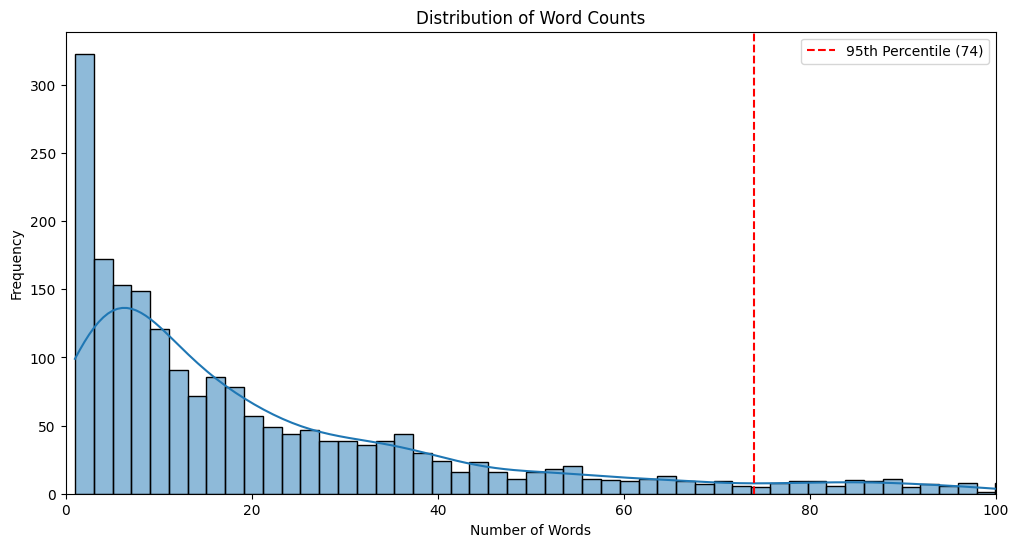

In [ ]:
import seaborn as sns
plt.figure(figsize=(12, 6))
sns.histplot(df_2000['word_count'], bins=50, kde=True)
plt.title('Distribution of Word Counts')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.xlim(0, 100)
plt.axvline(p95, color='r', linestyle='--', label=f'95th Percentile ({int(p95)})')
plt.legend()
plt.show()

In [ ]:
# Global Content Length
print(df_2000['word_count'].describe())

count    2000.000000
mean       21.619500
std        22.237445
min         1.000000
25%         6.000000
50%        13.000000
75%        30.000000
max       102.000000
Name: word_count, dtype: float64


In [ ]:
# Local Content Length
print(df_2000.groupby('score')['word_count'].describe())

# Insights:
# Higher reviews tend to have lower word counts (visible from the
# mean and each quartiles)

       count     mean        std  min   25%   50%    75%    max
score                                                          
1      400.0  25.1050  24.363146  1.0   8.0  16.0  35.25  101.0
2      400.0  29.0975  24.038044  1.0  10.0  22.0  39.00  102.0
3      400.0  23.5525  22.444970  1.0   7.0  16.0  34.00   95.0
4      400.0  19.0575  20.013634  1.0   5.0  12.0  25.00  100.0
5      400.0  11.2850  14.701330  1.0   3.0   6.0  13.00  100.0


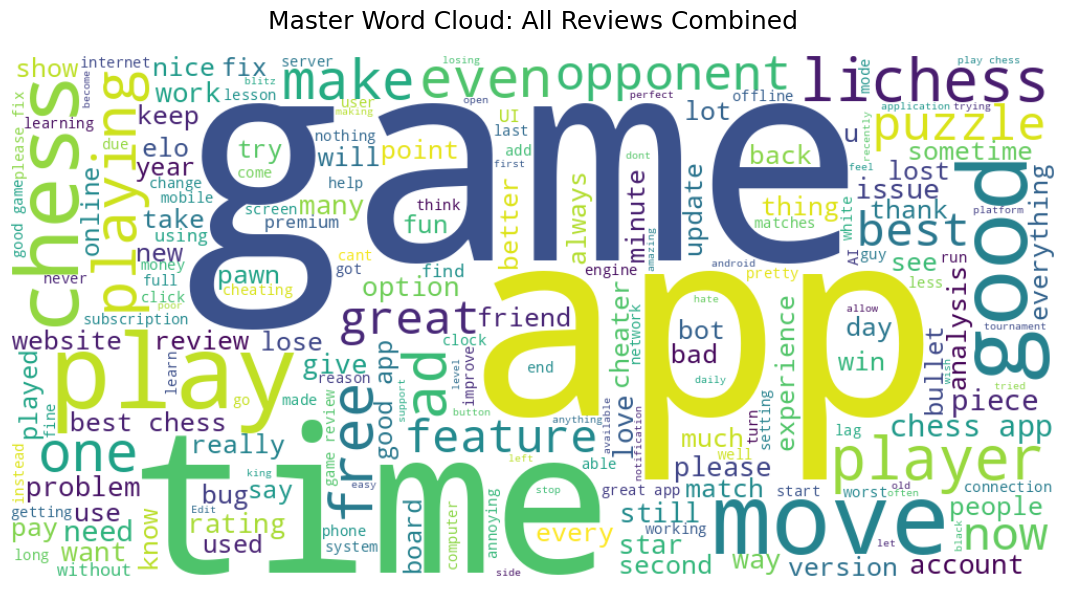

In [ ]:
# Global Word Cloud (with stopwords)
from wordcloud import WordCloud, STOPWORDS

all_text = " ".join(df_2000['content'].astype(str))

wordcloud = WordCloud(
  width=1000,
  height=500,
  background_color='white',
  # stopwords=custom_stopwords,
  colormap='viridis',
  min_font_size=10
).generate(all_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud_global_1, interpolation='bilinear')
plt.title('Master Word Cloud: All Reviews Combined', fontsize=18, pad=20)
plt.axis('off')
plt.tight_layout()
plt.show()

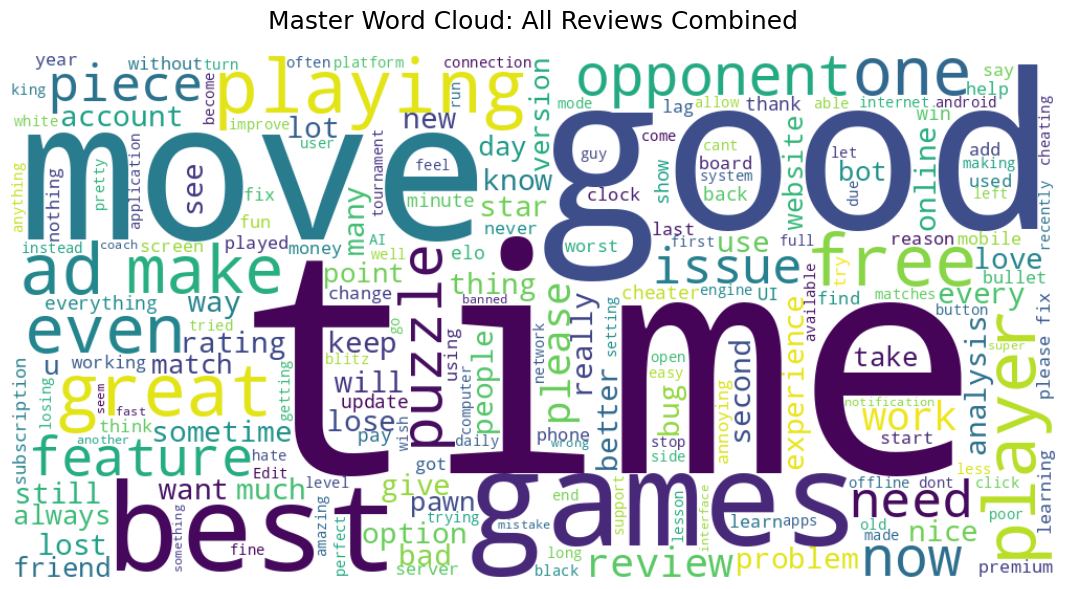

In [ ]:
# Global Word Cloud (without stopwords)
from wordcloud import WordCloud, STOPWORDS

all_text = " ".join(df_2000['content'].astype(str))

custom_stopwords = set(STOPWORDS)
custom_stopwords.update(["app", "game", "chess", "play", "lichess", "chesscom"])

wordcloud = WordCloud(
  width=1000,
  height=500,
  background_color='white',
  stopwords=custom_stopwords,
  colormap='viridis',
  min_font_size=10
).generate(all_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.title('Master Word Cloud: All Reviews Combined', fontsize=18, pad=20)
plt.axis('off')
plt.tight_layout()
plt.show()

Word cloud for 1 star reviews:


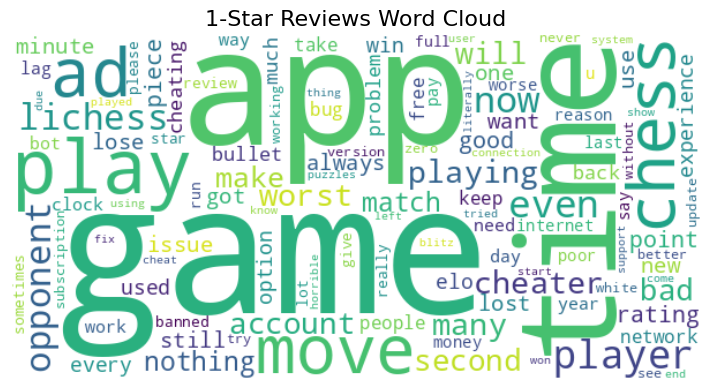

Word cloud for 2 star reviews:


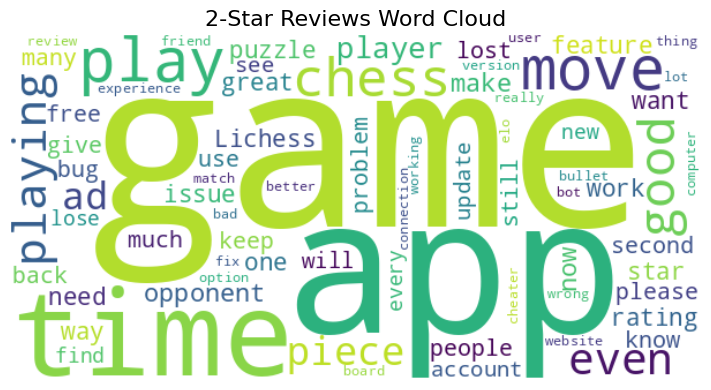

Word cloud for 3 star reviews:


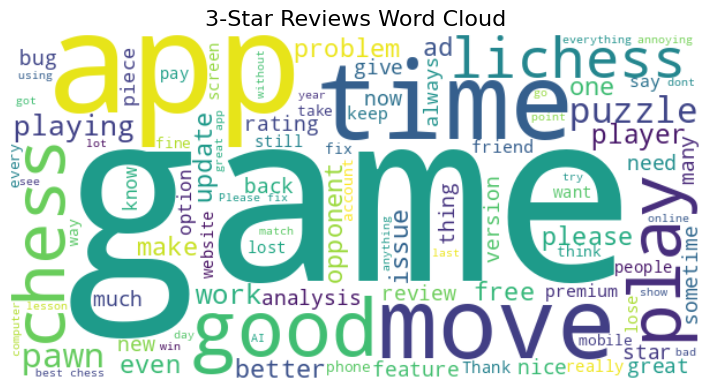

Word cloud for 4 star reviews:


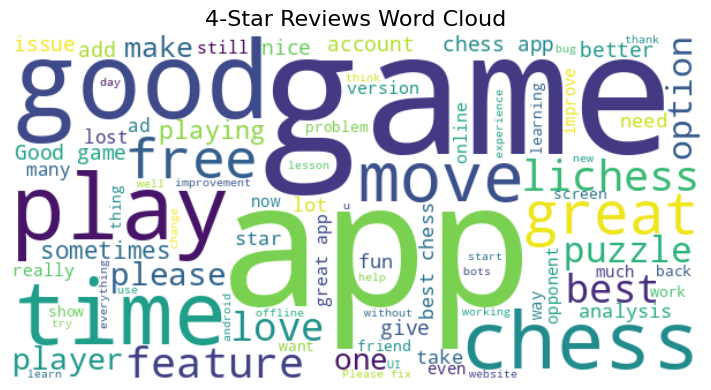

Word cloud for 5 star reviews:


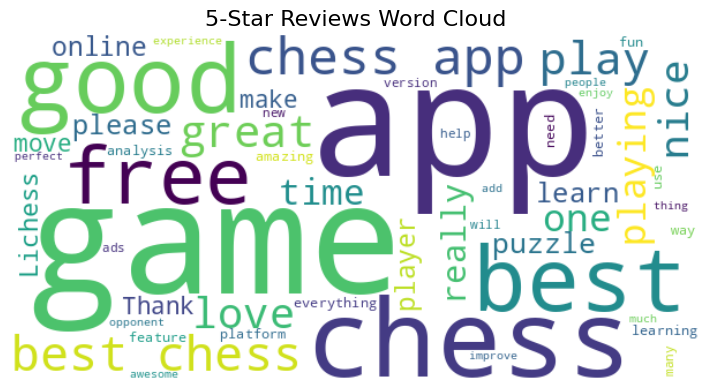

In [ ]:
# Local Word Cloud (with stopwords)
def generate_score_wordcloud(df, score):
  print(f"Word cloud for {score} star reviews:")

  text_data = df[df['score'] == score]['content'].astype(str)
  combined_text = " ".join(text_data)

  wordcloud = WordCloud(
      width=600,
      height=300,
      background_color='white',
      # stopwords=stopwords,
      colormap='viridis',
      min_font_size=10
  ).generate(combined_text)

  plt.figure(figsize=(8, 4))
  plt.imshow(wordcloud, interpolation='bilinear')
  plt.title(f'{score}-Star Reviews Word Cloud', fontsize=16)
  plt.axis('off') # Hide axes
  plt.tight_layout()
  plt.show()

for current_score in range(1, 6):
  generate_score_wordcloud(df_2000, current_score)

Word cloud for 1 star reviews:


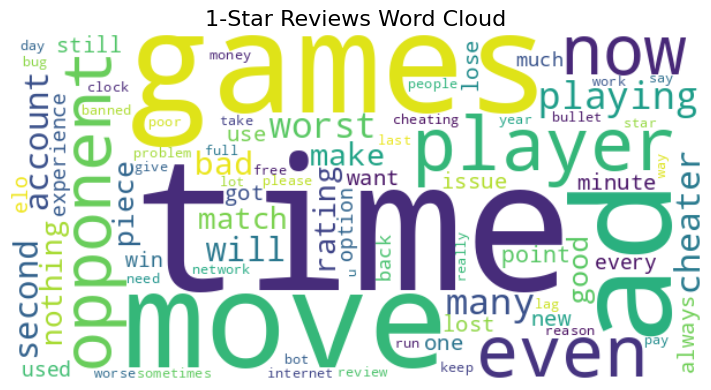

Word cloud for 2 star reviews:


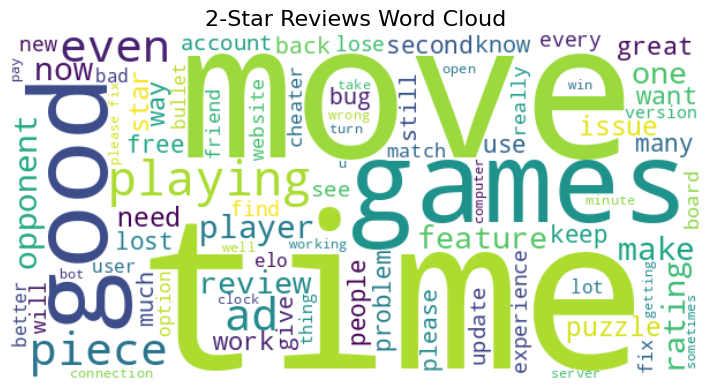

Word cloud for 3 star reviews:


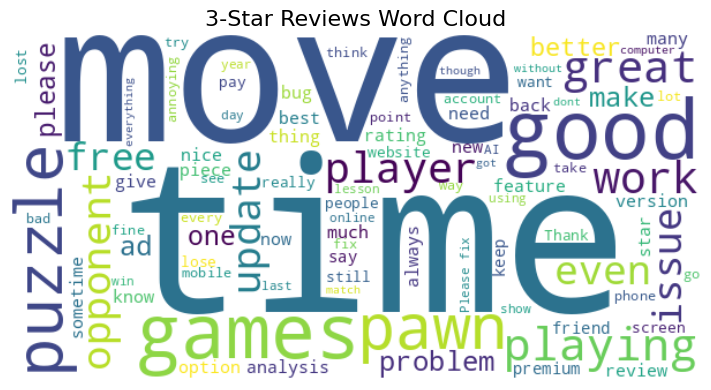

Word cloud for 4 star reviews:


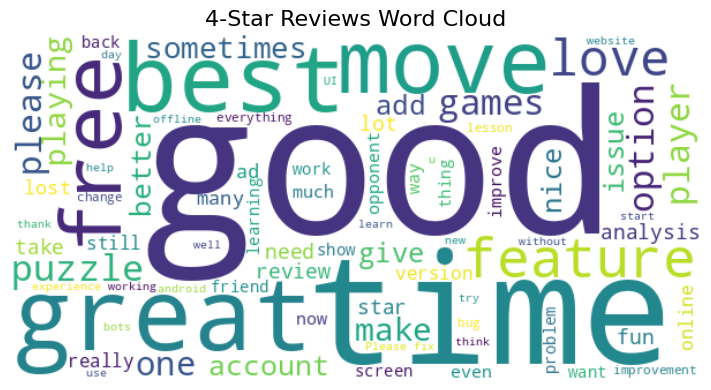

Word cloud for 5 star reviews:


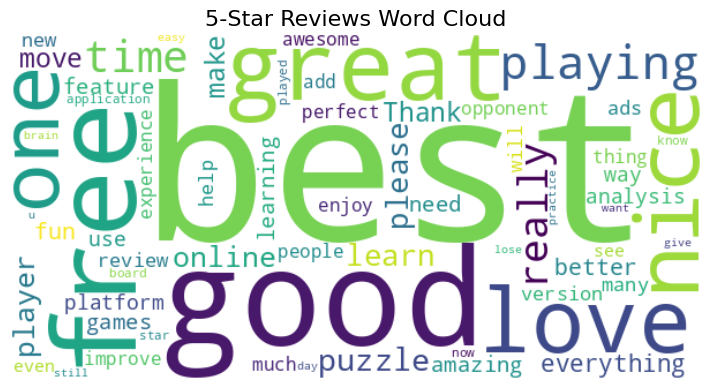

In [ ]:
# Local Word Cloud (without stopwords)
def generate_score_wordcloud(df, score, stopwords):
  print(f"Word cloud for {score} star reviews:")

  text_data = df[df['score'] == score]['content'].astype(str)
  combined_text = " ".join(text_data)

  wordcloud = WordCloud(
    width=600,
    height=300,
    ackground_color='white',
    stopwords=stopwords,
    colormap='viridis',
    min_font_size=10
  ).generate(combined_text)

  plt.figure(figsize=(8, 4))
  plt.imshow(wordcloud, interpolation='bilinear')
  plt.title(f'{score}-Star Reviews Word Cloud', fontsize=16)
  plt.axis('off')
  plt.tight_layout()
  plt.show()

for current_score in range(1, 6):
  generate_score_wordcloud(df_2000, current_score, custom_stopwords)

# Insights:
# Lower ratings: ad
# Higher ratings: best

In [ ]:
# Global Top Words
wc = WordCloud()
word_frequencies = wc.process_text(all_text)

top_50 = sorted(word_frequencies.items(), key=lambda x: x[1], reverse=True)[:50]

print("Top 50 most frequent words:")
for word, count in top_50:
  print(f"{word}: {count}")

Top 50 most frequent words:
game: 703
app: 586
time: 313
play: 247
move: 225
good: 206
chess: 169
lichess: 139
player: 137
playing: 130
free: 130
ad: 130
even: 118
one: 116
make: 115
opponent: 115
puzzle: 109
now: 106
great: 104
best: 102
feature: 98
chess app: 93
piece: 89
need: 89
issue: 84
please: 80
work: 78
problem: 77
love: 77
star: 76
rating: 76
account: 75
option: 75
want: 74
way: 74
many: 72
still: 72
give: 72
will: 69
lost: 69
use: 68
better: 68
best chess: 67
bug: 66
new: 65
much: 64
people: 64
thing: 63
sometime: 62
analysis: 61


In [ ]:
# Local Top Words
def generate_score_wordcloud(df, score):
  text_data = df[df['score'] == score]['content'].astype(str)
  combined_text = " ".join(text_data)

  wc = WordCloud()
  word_frequencies = wc.process_text(combined_text)

  top_50 = sorted(word_frequencies.items(), key=lambda x: x[1], reverse=True)[:50]

  print(f"Top 50 most frequent words for {score} star:")
  for word, count in top_50:
    print(f"{word}: {count}")
  print()

for current_score in range(1, 6):
  generate_score_wordcloud(df_2000, current_score)


# Insights:
# Lower ratings: ad
# Higher ratings: best

Top 50 most frequent words for 1 star:
game: 186
app: 149
time: 100
play: 63
move: 50
ad: 50
chess: 48
player: 41
even: 38
now: 35
lichess: 33
opponent: 33
playing: 30
many: 29
worst: 28
cheater: 27
account: 26
will: 26
second: 26
bad: 25
make: 24
nothing: 23
match: 23
rating: 23
piece: 22
good: 22
point: 22
always: 20
still: 20
lost: 20
one: 20
minute: 19
want: 19
new: 19
lose: 19
use: 19
issue: 19
got: 19
every: 18
experience: 18
used: 18
win: 17
option: 17
elo: 17
much: 16
back: 16
cheating: 16
bullet: 16
problem: 16
free: 15

Top 50 most frequent words for 2 star:
game: 184
app: 169
time: 95
play: 76
move: 74
chess: 56
good: 52
playing: 43
even: 39
piece: 39
ad: 37
player: 35
opponent: 34
make: 33
now: 32
rating: 29
one: 28
feature: 28
puzzle: 28
issue: 27
need: 27
star: 26
Lichess: 25
great: 24
want: 24
way: 24
work: 24
people: 22
second: 22
problem: 22
free: 22
use: 21
lost: 21
keep: 21
many: 21
please: 20
know: 20
give: 20
bug: 19
back: 19
still: 19
much: 19
account: 18
update: 

In [ ]:
# Global Unique Words
wc = WordCloud()
word_frequencies = wc.process_text(all_text)

top_50 = sorted(word_frequencies.items(), key=lambda x: x[1])[:50]

print("Top 50 unique words:")
for word, count in top_50:
  print(f"{word}: {count}")

Top 50 unique words:
publicity: 1
sold: 1
direct: 1
sustained: 1
violation: 1
Googe: 1
timely: 1
manner: 1
defending: 1
emailed: 1
directly: 1
integrity: 1
thier: 1
measure: 1
jumping: 1
wishes: 1
stealing: 1
minus: 1
premoved: 1
pressing: 1
requesting: 1
rematches: 1
blatant: 1
disregard: 1
reconnected: 1
4th: 1
forfeited: 1
FAQ: 1
akunku: 1
aktifkan: 1
dengan: 1
alasan: 1
yang: 1
tidak: 1
jelas: 1
soul: 1
resigned: 1
acceptable: 1
epidemic: 1
renewing: 1
opp: 1
brutally: 1
annihilated: 1
booty: 1
cheeks: 1
uneven: 1
truth: 1
protection: 1
related: 1
observations: 1


In [ ]:
# Local Unique Words
def generate_score_wordcloud(df, score):
  text_data = df[df['score'] == score]['content'].astype(str)
  combined_text = " ".join(text_data)

  wc = WordCloud()
  word_frequencies = wc.process_text(combined_text)

  top_10 = sorted(word_frequencies.items(), key=lambda x: x[1])[:10]

  print(f"Top 10 unique words for {score} star:")
  for word, count in top_10:
    print(f"{word}: {count}")
  print()

for current_score in range(1, 6):
  generate_score_wordcloud(df_2000, current_score)

Top 10 unique words for 1 star:
nets: 1
publicity: 1
sold: 1
decides: 1
live: 1
ignored: 1
direct: 1
sustained: 1
violation: 1
Googe: 1

Top 10 unique words for 2 star:
Factor: 1
Verification: 1
entered: 1
username: 1
hardly: 1
suggest: 1
maintained: 1
fairly: 1
handicaps: 1
JIO: 1

Top 10 unique words for 3 star:
unfollow: 1
cool: 1
literally: 1
counting: 1
7secs: 1
intermittently: 1
tje: 1
bored: 1
spam: 1
wont: 1

Top 10 unique words for 4 star:
weak: 1
plzz: 1
effort: 1
mid: 1
astonishing: 1
couple: 1
Innovation: 1
Popular: 1
priced: 1
engaging: 1

Top 10 unique words for 5 star:
son: 1
hrs: 1
apart: 1
smooth: 1
dont: 1
continue: 1
develope: 1
cheese: 1
snappy: 1
matchmaking: 1



In [ ]:
df_2000.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   content     2000 non-null   object
 1   score       2000 non-null   int64 
 2   word_count  2000 non-null   int64 
 3   char_count  2000 non-null   int64 
 4   contracted  2000 non-null   object
dtypes: int64(3), object(2)
memory usage: 78.3+ KB


In [ ]:
df_final = df_2000[['contracted', 'score']].copy()

In [ ]:
df_final.rename(columns={'contracted':'content'}, inplace=True)

In [ ]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   content  2000 non-null   object
 1   score    2000 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 31.4+ KB


In [ ]:
df_final.to_csv('balanced_cleaned.csv')